# Variant Well Profiles

In [38]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from collections import defaultdict
import umap
%matplotlib inline

controls = {
    "TC": ["EGFP"],
    "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
    "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
    # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
    # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
    # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
    # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
}

ctrl_alleles = [k_v for k_v in controls.values()]
ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
ctrl_alleles_flat

/home/shenrunx/software/anaconda3/envs/cytoself/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['EGFP', 'RHEB', 'MAPK9', 'PRKACB', 'SLIRP', 'ALK', 'ALK_Arg1275Gln', 'PTK2B']

## Loading data

### Read in the classifier metrics

In [20]:
# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]
thresh = 3
min_class_num = 2

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")
    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])


## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()

misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)
misloc_wt = (
    local_wtvar
    .with_columns(pl.col("allele_0").str.replace("_.*", "").alias("wt"))
    .select("wt")
    .to_series()
    .unique()
    .to_list()
)
all_alleles = misloc_alleles + misloc_wt

len(all_alleles)

1242

In [24]:
misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        columns="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

sig_misloc_alleles = misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]
# sig_misloc_alleles

### Read in cell profiles of mislocalized alleles

In [25]:
# Paths
profile_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles"
pass_qc_prof_dir = f"{profile_dir}/" + "{}/profiles_tcdropped_filtered_var_mad_outlier_featselect.parquet"

# Get meta features
b7_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[0])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

b8_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[1])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

cell_alleles = pl.concat([b7_alleles.collect(), b8_alleles.collect()])

In [26]:
prof_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles/{}/profiles.parquet"

b7_prof = pl.scan_parquet(
    prof_dir.format(batches[0])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)
b8_prof = pl.scan_parquet(
    prof_dir.format(batches[1])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)

gfp_int = [i for i in b7_prof.schema.keys() if "GFP" in i]
gfp_int = ["Metadata_CellID"] + gfp_int

profiles = pl.concat([
    b7_prof.select(gfp_int).collect(),
    b8_prof.select(gfp_int).collect(),
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
profiles = cell_alleles.join(profiles, on="Metadata_CellID", how="left")

### Aggregate to well profiles

In [27]:
well_profiles = (
    profiles.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
    )
    .unique()
    .drop_nulls("Metadata_gene_allele")
)
well_profiles

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_17_B7A…","""K05""","""ACSF3_Pro243Le…",0.413121,-0.143613,-0.177221,-0.095518,0.327761,0.908475,0.991165,0.0,0.0,0.0,0.994634,1.0,0.0,0.0,0.0,0.846397,0.998776,0.997006,0.466218,0.155932,0.156091,0.156224,1.070995,1.773797,5.505944,5.500486,5.51827,0.769497,11.809891,0.0754,1.0,1.0,1.0,1.0,…,2.051552,0.297647,0.345187,0.242873,0.253586,0.0,0.0,0.0,0.0,0.270829,0.288061,0.305874,0.292884,0.049971,0.061637,0.045376,0.040715,0.0,0.0,0.0,0.0,0.049731,0.047911,0.059057,0.04889,0.025691,0.030952,0.019888,0.020813,0.0,0.0,0.0,0.0,0.022952,0.024599,0.027195,0.02511
"""2024_02_05_B8A…","""M10""","""TAT_Pro220Ser""",0.125754,-0.090317,-0.11097,-0.073137,0.325081,0.764207,1.0,0.0,0.0,0.0,0.99114,1.0,0.0,0.0,0.0,0.583402,1.0,1.0,1.163993,0.444671,0.443912,0.444677,3.916546,0.63915

In [32]:
well_profiles_plate_agg = (
    well_profiles.group_by(["Metadata_gene_allele", "Metadata_Well"])
    .agg(
        pl.col(col).median().alias(col)
        for col in well_profiles.columns
        if not col.startswith("Metadata_")
    ).with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(ctrl_alleles_flat))
        .then(pl.lit("Control"))
        .otherwise(pl.lit("Allele"))
        .alias("Metadata_control_type")
    )
)
well_profiles_plate_agg

Metadata_gene_allele,Metadata_Well,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,Cytoplasm_Correlation_Manders_DNA_GFP,…,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256,Metadata_control_type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""PKP2_Asp26Asn""","""J05""",0.242732,-0.084545,-0.094204,-0.078904,0.090251,0.252538,0.999944,0.0,0.0,0.0,0.999179,1.0,0.0,0.0,0.0,0.604992,1.0,1.0,0.492204,0.222499,0.222357,0.222784,1.591241,1.678057,4.027522,4.030349,4.030009,0.512929,9.870206,0.08102,0.993361,0.987712,0.987733,0.987744,0.992455,…,0.114551,0.141122,0.097148,0.137026,0.0,0.0,0.0,0.0,0.118207,0.116458,0.114867,0.119084,0.016983,0.02026,0.013624,0.018948,0.0,0.0,0.0,0.0,0.018782,0.016313,0.016986,0.015888,0.007623,0.010242,0.006438,0.009572,0.0,0.0,0.0,0.0,0.008237,0.008227,0.007716,0.00801,"""Allele"""
"""COMP_Gly207Asp…","""L01""",0.255645,-0.097804,-0.121966,-0.072859,0.186868,0.627017,0.9393,0.0,0.0,0.0,0.98829,1.0,0.0,0.0,0.0,0.668471,0.997089,0.999155,0.920583,0.58355,0.582686,0.582911,2.544093,0.85

In [35]:
well_profiles_plate_agg.select(pl.col("Metadata_control_type").unique()).to_series().to_list()

['Allele']

In [33]:
well_profiles_plate_agg = well_profiles_plate_agg.with_columns(
    pl.when(pl.col("Metadata_gene_allele").str.contains("_"))
    .then(pl.lit("Reference"))
    .otherwise(pl.lit("Variant"))
    .alias("Metadata_variant_type")
).sort(
    pl.col(["Metadata_gene_allele"])
)
well_profiles_plate_agg

Metadata_gene_allele,Metadata_Well,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,Cytoplasm_Correlation_Manders_DNA_GFP,…,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256,Metadata_control_type,Metadata_variant_type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""ACACB""","""B08""",0.195919,-0.153347,-0.164623,-0.111994,0.193157,0.55024,0.879427,0.249011,0.156619,0.398351,0.918376,1.0,0.632826,0.758425,0.146378,0.652337,1.0,0.989231,0.370669,0.092233,0.092464,0.092172,0.76614,2.511498,10.684477,10.703906,10.698475,1.22723,19.657222,0.042385,1.0,1.0,1.0,1.0,1.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Allele""","""Variant"""
"""ACACB_Val958Me…","""D08""",0.154555,-0.104549,-0.113716,-0.077231,0.176729,0.433291,0.907205,0.023894,0.010665,0.105041,0.927624,1.0,1.0,1.0,0.999948,0.581201,1.0,0.996895,0.292652,0.091139,0.090981,0.091331,0.774258,3.105059,10.760716,10.735919,10.785157,1.196605,20.143291,0.040664,1.0,1.0,1.0,1.0,1.0,…,0.0,0.0,0.0,0.0,0.

In [36]:
# well_profiles_plate_agg.filter(pl.col("Metadata_gene_allele").str.contains("ALK")) #.filter(pl.col("Control_type") == "Control")

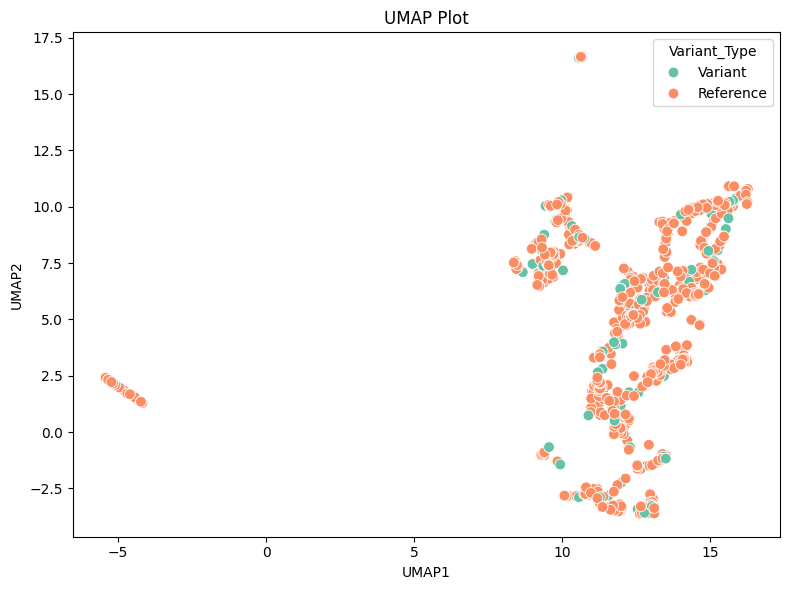

In [44]:
from sklearn.preprocessing import StandardScaler

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
df = well_profiles_plate_agg.select(pl.col([col for col in well_profiles_plate_agg.columns if not col.startswith("Metadata_")]))

# Standardize the features before PCA
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

umap_result = umap_model.fit_transform(df.to_numpy())
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = well_profiles_plate_agg["Metadata_gene_allele"].to_numpy()
umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_variant_type", palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [45]:
umap_df[umap_df["UMAP1"]<5]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
85,-5.408559,2.401598,BCL10,Variant,Allele
86,-5.443964,2.436691,BCL10_Leu8Leu,Reference,Allele
158,-4.339586,1.454342,DES,Variant,Allele
159,-4.822032,1.871822,DES_Ala135Val,Reference,Allele
160,-4.325285,1.440421,DES_Ala213Val,Reference,Allele
161,-4.478699,1.580750,DES_Ala237Thr,Reference,Allele
165,-5.196033,2.195946,DES_Ala397Thr,Reference,Allele
166,-4.363954,1.471305,DES_Arg127Pro,Reference,Allele
167,-4.976421,2.001152,DES_Arg150Gln,Reference,Allele
168,-4.243656,1.365429,DES_Arg16Cys,Reference,Allele


In [48]:
umap_df[(umap_df["UMAP1"]>5)&(umap_df["UMAP2"]>15)]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
267,10.670685,16.623707,GATA2_Cys373Arg,Reference,Allele
482,10.698064,16.720434,NMNAT1,Variant,Allele
483,10.612729,16.633656,NMNAT1_Arg207Trp,Reference,Allele
485,10.680852,16.699604,NMNAT1_Asn273Asp,Reference,Allele
487,10.589437,16.647108,NMNAT1_Leu153Val,Reference,Allele
488,10.634657,16.653881,NMNAT1_Ser255Asn,Reference,Allele
489,10.671806,16.605488,ORC6,Variant,Allele
490,10.619808,16.666800,ORC6_Tyr232Ser,Reference,Allele
552,10.573025,16.600382,PLA2G6,Variant,Allele
670,10.656266,16.667801,SNIP1,Variant,Allele


## Co-localization patterns

In [53]:
## Select colocalization metrics between meaningful channels
## Select columns that contain "Correlation" but not "Brightfield", brightfield doesn't provide useful information here
colocal_cols = [col for col in well_profiles.columns if "Correlation" in col and "Brightfield" not in col]
colocal_col_cat = set(["_".join(col.split('_')[1:3]) for col in colocal_cols])
print(colocal_col_cat)

colocal_col_dict = defaultdict(list)
for col in colocal_cols:
    colocal_col_dict["_".join(col.split('_')[1:3])].append(col)
# colocal_col_dict

{'Correlation_Correlation', 'Correlation_Overlap', 'Correlation_Manders', 'Texture_Correlation', 'Correlation_K', 'Correlation_RWC', 'Correlation_Costes'}


## WT gene well profiles

In [54]:
well_profiles_wt = well_profiles.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)
well_profiles_wt

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A…","""B08""","""ACACB""",0.209386,-0.102414,-0.100254,-0.10583,0.218471,0.55103,0.872907,0.009793,0.000829,0.078723,0.916885,1.0,1.0,0.51685,1.0,0.567537,1.0,1.0,0.135624,0.09144,0.092116,0.091375,0.690829,6.608265,10.687915,10.700838,10.70103,1.233437,17.793319,0.048558,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_01_22_B7A…","""B08""","""ACACB""",0.20117,-0.09214,-0.086157,-0.080617,0.185177,0.527714,0.873305,0.0,0.0,0.0,0.958477,1.0,0.0,0.0,0.0,0.665684,1.0,0.998969,0.363056,0.105012,0.104847,0.104458,0.763093,2.307217,9.258984,9.228502,9.441518,1.229213,21.36025,0.040013,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

### Co-localization patterns

                                                mean       std  Corr_cat
index                                                                   
Nuclei_Correlation_Correlation_GFP_Mito     0.395787  0.212546  GFP_Mito
Cytoplasm_Correlation_Correlation_GFP_Mito  0.612596  0.194620  GFP_Mito
Cells_Correlation_Correlation_GFP_Mito      0.560901  0.180248  GFP_Mito
Nuclei_Correlation_Correlation_DNA_GFP     -0.131063  0.451859   DNA_GFP
Cytoplasm_Correlation_Correlation_DNA_GFP   0.283727  0.159057   DNA_GFP
Cells_Correlation_Correlation_DNA_GFP       0.197164  0.355795   DNA_GFP
Nuclei_Correlation_Correlation_AGP_GFP      0.199590  0.259077   AGP_GFP
Cytoplasm_Correlation_Correlation_AGP_GFP   0.219036  0.120225   AGP_GFP
Cells_Correlation_Correlation_AGP_GFP       0.192089  0.129070   AGP_GFP


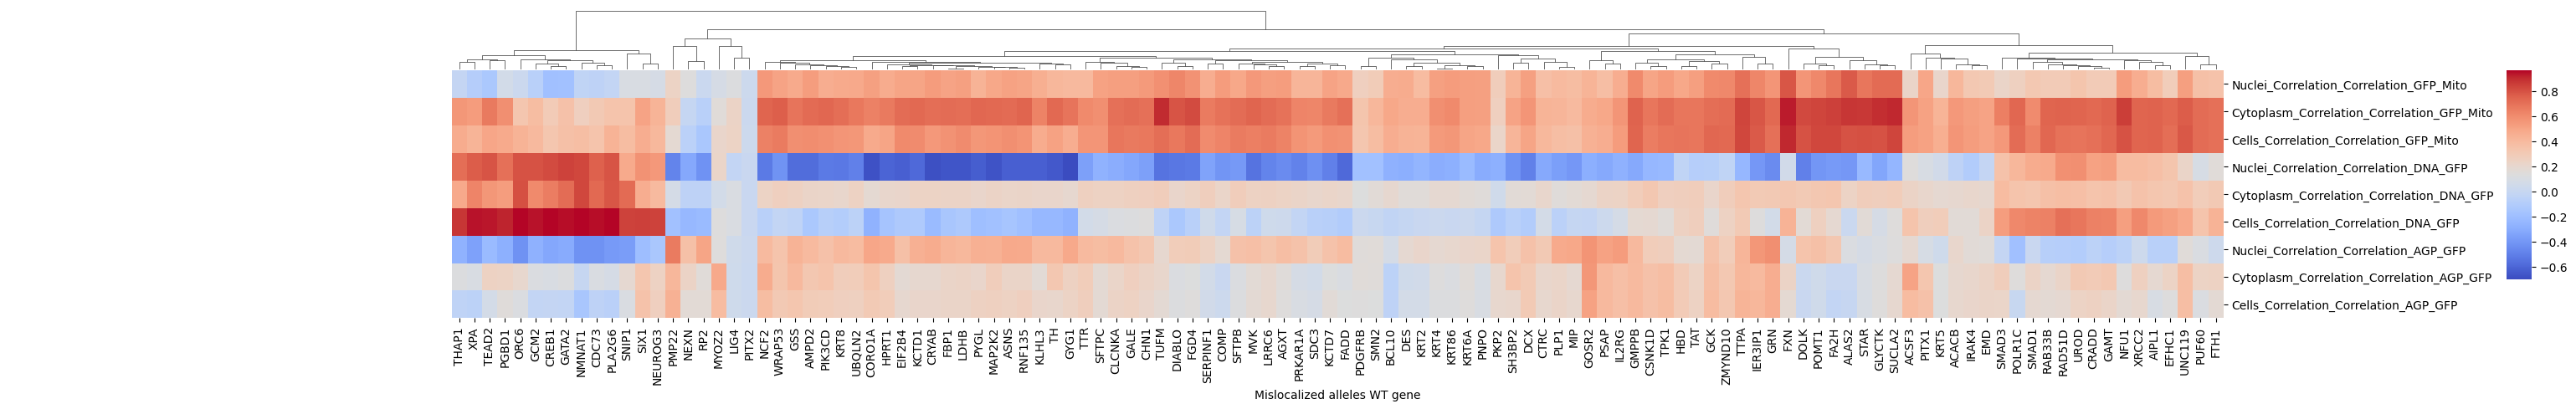

In [ ]:
well_profiles_wt_gene = well_profiles_wt.group_by("Metadata_gene_allele").agg(
    pl.col(col).median().alias(col)
    for col in colocal_cols
).select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

## Calculate mean and standard deviation for each column
column_stats = well_profiles_wt_gene[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T.reset_index()
column_stats["Corr_cat"] = column_stats["index"].apply(lambda x: "_".join(x.split("_")[-2:]))
## Sort columns by the sum of mean and std in descending order
sorted_columns = column_stats.sort_values(by=["Corr_cat","index"], ascending=False)
sorted_columns.set_index("index", inplace=True)
print(sorted_columns)

# sorted_columns.loc[colocal_col_dict["Correlation_Correlation"]]
# sorted_columns.loc[colocal_col_dict["Correlation_Costes"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_RWC"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_Manders"]] ## means nearly all to 1, meaningless here

# ## filter out corr columns with mean <= 1
# sorted_columns = sorted_columns[sorted_columns["mean"] > 1]
# display(sorted_columns)

g = sns.clustermap(well_profiles_wt_gene[sorted_columns.index].T, figsize=(30, 5), cmap="coolwarm", 
xticklabels=1, cbar_pos=(1., .32, .01, .5),
row_cluster=False, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=10)
rot_xticks = g.ax_heatmap.set_xlabel("Mislocalized alleles WT gene")
g.fig.suptitle("Mislocalized Variants' Reference Alleles: Pearson's Correlation between Channels") 

## Well Profiles Visualization

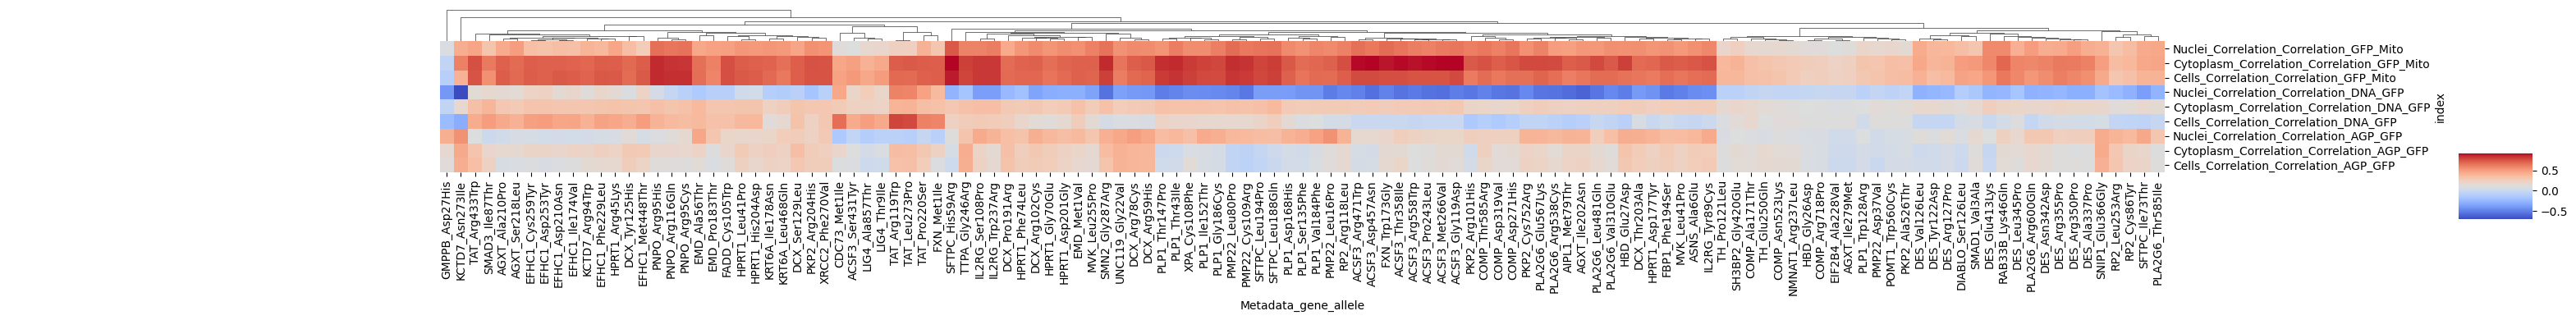

In [ ]:
well_profiles_var = well_profiles.filter(
    pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)

well_profiles_var_allele = well_profiles_var.group_by(["Metadata_gene_allele"]).agg(
    pl.col(col).median().alias(col)
        for col in colocal_cols
).unique().select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

# Calculate mean and standard deviation for each column
column_stats = well_profiles_var_allele[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T
# Sort columns by the sum of mean and std in descending order
# sorted_columns = column_stats.sort_values(by=["mean", "std"], ascending=False)

# display(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index])

# sns.set(font_scale=.8)
g = sns.clustermap(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index].T, # standard_scale=0, 
yticklabels=1, xticklabels=1, cbar_pos=(1., .32, .03, .2), figsize=(30, 4), 
cmap="coolwarm", row_cluster=False, col_cluster=True) ## , "viridis", z_score=0, 
g.fig.suptitle("Mislocalized Variants: Pearson's Correlation between Channels") 

# gfp_cols = [col for col in well_profiles_merge_plate.columns if "GFP" in col]
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in gfp_cols if well_profiles_merge_plate[col].std() > 2] + ["Metadata_gene_allele"]
# )

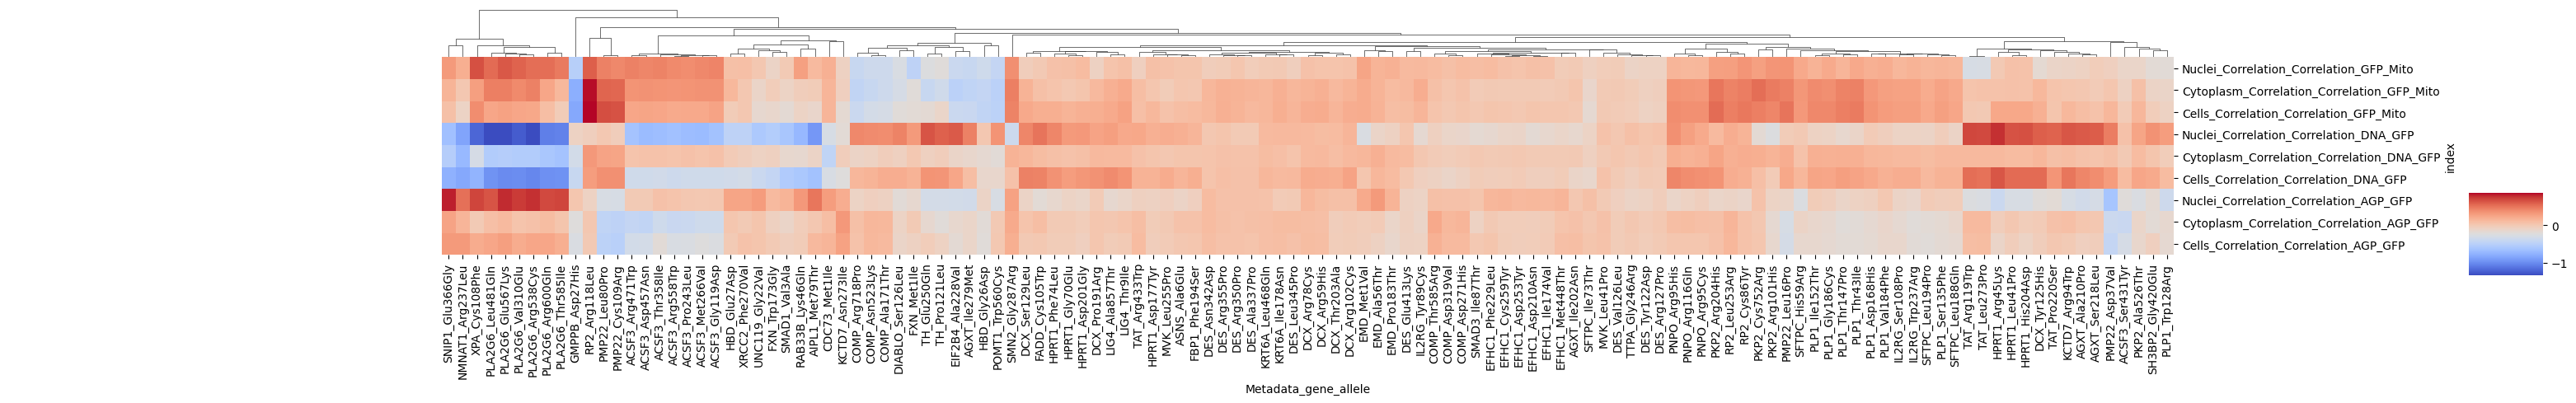

In [57]:
# display(well_profiles_var_allele[sorted_columns.index])
# display(well_profiles_wt_gene[sorted_columns.index])

well_profiles_var_allele_regroup = well_profiles_var_allele.loc[sig_misloc_alleles,].reset_index()
well_profiles_var_allele_regroup["Gene"] = well_profiles_var_allele_regroup["Metadata_gene_allele"].apply(lambda x: x.split("_")[0])

misloc_scores = pd.DataFrame()
for gene, group in well_profiles_var_allele_regroup.groupby("Gene"):
    # print(gene)
    # display(group)
    group = group.set_index("Metadata_gene_allele")
    group = group - well_profiles_wt_gene.loc[gene]
    misloc_scores = pd.concat([misloc_scores, group], axis=0)

# misloc_scores.columns = [col+"_var-wt" for col in misloc_scores.columns]
misloc_scores

sns.clustermap(misloc_scores.loc[sig_misloc_alleles,sorted_columns.index].T, xticklabels=1, cbar_pos=(1., .32, .03, .2),
figsize=(30, 5), cmap="coolwarm", row_cluster=False, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 

In [58]:
misloc_scores

,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Costes_AGP_GFP,Cells_Correlation_Costes_DNA_GFP,Cells_Correlation_Costes_GFP_AGP,Cells_Correlation_Costes_GFP_DNA,Cells_Correlation_Costes_GFP_Mito,Cells_Correlation_Costes_Mito_GFP,Cells_Correlation_K_AGP_GFP,...,Nuclei_Texture_Correlation_GFP_10_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Nuclei_Texture_Correlation_GFP_20_00_256,Nuclei_Texture_Correlation_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_20_02_256,Nuclei_Texture_Correlation_GFP_20_03_256,Nuclei_Texture_Correlation_GFP_5_00_256,Nuclei_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_5_03_256
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
ACSF3_Arg471Trp,-0.327371,-0.346308,0.237516,-0.011241,-0.002811,0.000000,0.106152,0.000000,0.000150,-0.078716,...,-0.533639,-0.520072,0.000000,0.000000,0.000000,0.000000,-0.451729,-0.477343,-0.465232,-0.491391
ACSF3_Arg558Trp,-0.283388,-0.363385,0.211762,-0.008070,-0.005813,0.000000,0.098977,0.000000,0.000108,-0.092210,...,-0.548224,-0.521291,0.000000,0.000000,0.000000,0.000000,-0.500850,-0.545542,-0.511457,-0.539768
ACSF3_Asp457Asn,-0.321329,-0.348617,0.241134,-0.005197,-0.003620,0.000000,0.064869,-0.000177,-0.000763,-0.082921,...,-0.547559,-0.521004,0.000000,0.000000,0.000000,0.000000,-0.495091,-0.520600,-0.515182,-0.541976
ACSF3_Thr358Ile,-0.198333,-0.339428,0.233743,-0.007262,-0.006532,0.000000,0.355117,0.000000,0.000101,-0.081000,...,-0.517312,-0.504952,0.000000,0.000000,0.000000,0.000000,-0.420288,-0.473053,-0.431365,-0.493689
ACSF3_Met266Val,-0.232930,-0.348781,0.216314,-0.014912,-0.005074,0.000000,-0.010911,0.000000,0.000150,-0.139852,...,-0.502904,-0.490095,0.000000,0.000000,0.000000,0.000000,-0.400544,-0.472104,-0.419861,-0.448663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TH_Pro121Leu,-0.094620,0.329471,-0.124185,-0.346618,-0.220672,-0.136828,-0.741373,-0.076857,-0.108783,-1.542623,...,0.926591,1.011336,1.046677,1.103011,1.023487,1.097005,0.697200,0.839464,0.711625,0.840803
TTPA_Gly246Arg,-0.008710,-0.053392,-0.040964,0.000000,0.000319,0.000000,0.061269,0.000104,0.000000,-2.499226,...,-0.020095,-0.004407,0.025901,0.094588,0.016992,0.061874,-0.086938,-0.042438,-0.080490,-0.064098
UNC119_Gly22Val,0.025281,-0.391414,-0.162012,0.000000,-0.000209,0.000000,-0.246847,-0.002621,-0.000193,1.069590,...,-0.066738,-0.087976,-0.032702,-0.096823,-0.022201,-0.117062,-0.046942,-0.082244,0.033964,0.023552


In [59]:
[idx for idx in misloc_scores.index if "PLA2G6" in idx]

['PLA2G6_Glu567Lys',
 'PLA2G6_Arg600Gln',
 'PLA2G6_Leu481Gln',
 'PLA2G6_Val310Glu',
 'PLA2G6_Thr585Ile',
 'PLA2G6_Arg538Cys']

In [61]:
# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(misloc_scores.loc[sig_misloc_alleles, sorted_columns.index])

/tmp/ipykernel_151077/643913833.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type,
/tmp/ipykernel_151077/643913833.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Variant_Type")


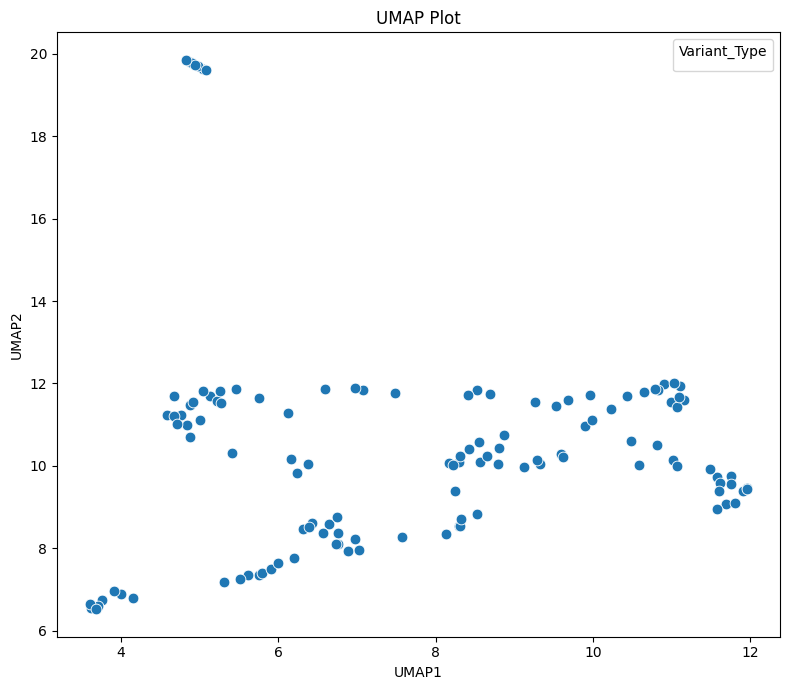

In [62]:
# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(8, 7))
sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [63]:
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = sig_misloc_alleles

In [64]:
umap_df[umap_df["UMAP2"]>18]["Metadata_gene_allele"].to_list()

['ACSF3_Arg471Trp',
 'ACSF3_Arg558Trp',
 'ACSF3_Asp457Asn',
 'ACSF3_Thr358Ile',
 'ACSF3_Met266Val',
 'ACSF3_Gly119Asp',
 'ACSF3_Pro243Leu']

In [65]:
umap_df[umap_df["UMAP1"]<4.5]["Metadata_gene_allele"].to_list()

['PLA2G6_Glu567Lys',
 'PLA2G6_Arg600Gln',
 'PLA2G6_Leu481Gln',
 'SNIP1_Glu366Gly',
 'PLA2G6_Val310Glu',
 'XPA_Cys108Phe',
 'NMNAT1_Arg237Leu',
 'PLA2G6_Thr585Ile',
 'PLA2G6_Arg538Cys']

In [53]:
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in well_profiles_merge_plate.columns if not col.startswith("Metadata_")] + ["Metadata_gene_allele"]
# ).to_pandas().set_index("Metadata_gene_allele").loc[misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"],:]

# # from sklearn.preprocessing import StandardScaler
# # scaler = StandardScaler()
# # well_profiles_scaled = pd.DataFrame(scaler.fit_transform(well_profiles_merge_plate), columns=well_profiles_merge_plate.columns, index=well_profiles_merge_plate.index)
# # display(well_profiles_scaled)

# sns.clustermap(well_profiles_scaled, figsize=(20, 40), standard_scale=0, cmap="coolwarm", row_cluster=True, col_cluster=True) ## , "viridis"
# plt.show()